<a href="https://colab.research.google.com/github/chns8656ghub/ML_Demo/blob/main/Exercise_day5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install into the Python environment used by this notebook.
import sys

# Run pip from Python so the installation cell is also valid in a .py file.
import subprocess

# Supply the image reader, model layers and small classifiers used below.
packages = [
    "rasterio==1.4.3",
    "timm==1.0.15",
    "einops==0.8.1",  # Match the model's configuration reader and classifier release.
    "PyYAML==6.0.2",
    "scikit-learn==1.5.2",
]
# Stop here if installation fails, before later imports hide the cause.
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *packages])
# This message marks successful installation; no model has been run yet.
print("Exercise libraries installed.")

Exercise libraries installed.


In [ ]:
# Paths keep downloaded data and reusable features easy to find in Colab's Files panel.
from pathlib import Path

# Load the model configuration and import its downloaded Python implementation.
import json, importlib.util

# Reproduce the same image selection each time.
import random

# Fetch public model and dataset files without an account token.
from urllib.request import urlopen, urlretrieve

# Read only the selected image tiles from the public dataset archive.
import zipfile

# Arrays hold image bands and the numerical feature tables.
import numpy as np

# Tables keep filenames, classes and measured results aligned.
import pandas as pd

# Rasterio reads the multispectral TIFF band values.
import rasterio

# PyTorch runs the frozen foundation model.
import torch

# Matplotlib displays the satellite images and comparison plots.
import matplotlib.pyplot as plt

# Use the free Colab GPU for image encoding; small classifiers will use CPU.
DEVICE = "cuda"
# If a GPU is unavailable, uncomment the following line and allow a slower run.
# DEVICE = "cpu"
# Give a clear remedy if Colab was connected without a GPU.
if DEVICE == "cuda" and not torch.cuda.is_available():
    # The CPU alternative changes the execution device, not the experiment.
    raise RuntimeError("Select a GPU runtime, or uncomment DEVICE = 'cpu'.")
# Keep all working files together under the notebook's current directory.
ROOT = Path.cwd() / "reusable_embeddings"
# Separate inputs from the feature tables and figures we create.
DATA, MODEL, RESULTS = [ROOT / name for name in ["data", "model", "results"]]
# These directories may already exist when a cell is repeated.
for folder in [DATA, MODEL, RESULTS]:
    # Parent directories are created automatically on the first run.
    folder.mkdir(parents=True, exist_ok=True)
# Limit CPU thread contention during the small downstream classifier fits.
torch.set_num_threads(2)
# Confirm the selected accelerator before downloading the large inputs.
print("Device:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")

Device: Tesla T4


In [ ]:
# Prithvi-EO-2.0-300M was pretrained on Earth-observation imagery.
REPO = "ibm-nasa-geospatial/Prithvi-EO-2.0-300M"
# These download addresses select the model release used in this exercise.
MODEL_URL = (
    f"https://huggingface.co/{REPO}/resolve/"
    # This address selects the pretrained files used for the exercise.
    "9eb1b1102806593963daa333bcc491b1c6f8562f"
)
# The configuration, architecture and learned weights are all needed to load the encoder.
for name in ["config.json", "prithvi_mae.py", "Prithvi_EO_V2_300M.pt"]:
    # Existing complete downloads can be reused within the same runtime.
    target = MODEL / name
    # A temporary filename avoids treating an interrupted download as complete.
    if not target.exists():
        # Show which file is currently downloading; the weights are the large one.
        print("Downloading", name, flush=True)
        # Keep a partially downloaded file separate from the usable file.
        partial = target.with_suffix(target.suffix + ".part")
        # Stream the public file to disk rather than keeping its bytes in memory.
        urlretrieve(f"{MODEL_URL}/{name}", partial)
        # Only a completed transfer becomes the file used by the next cells.
        partial.replace(target)
# Downloading weights does not train or fine-tune the model.
print("Prithvi model files are ready.")

Prithvi model files are ready.


In [ ]:
# EuroSAT provides 13-band Sentinel-2 tiles and spatially separated split lists.
DATA_URL = (
    "https://huggingface.co/datasets/torchgeo/eurosat/resolve/"
    # The split lists and image archive come from this same dataset release.
    "68508cef507a0dca26a913adda91d5fc60b28d89"
)
# Keep filenames from the official training and test regions separate.
lists = {}
# Read the small split lists before downloading the image archive.
for split in ["train", "test"]:
    # Each line names an image; our archive contains its TIFF version.
    with urlopen(f"{DATA_URL}/eurosat-spatial-{split}.txt") as response:
        # Convert the listed extension to .tif while preserving image identity.
        lines = response.read().decode("utf-8").splitlines()
        # Remove empty lines while keeping the official image identities.
        lists[split] = [
            Path(line).with_suffix(".tif").name
            # The archive's TIFF filenames match these converted names.
            for line in lines
            if line.strip()
        ]
# The filename prefix is the reference land-cover class.
classes = sorted({name.split("_")[0] for name in lists["train"]})
# Build a 30-per-class training pool and a separate 5,000-image evaluation set.
train_names, test_names = [], []
# Select each class independently so the small training pool stays balanced.
for label in classes:
    # Sort filenames before sampling so the selection can be repeated.
    candidates = sorted(n for n in lists["train"] if n.startswith(label + "_"))
    # Thirty candidates per class allow three different 20-label training choices later.
    train_names.extend(random.Random(42).sample(candidates, 30))
    # Test candidates come only from the official spatial test regions.
    candidates = sorted(n for n in lists["test"] if n.startswith(label + "_"))
    # Reserve 40 tiles per class outside the fixed evaluation subset.
    reserved = set(random.Random(42).sample(candidates, 20))
    # Complete that reservation without selecting any image twice.
    reserved.update([n for n in candidates if n not in reserved][:20])
    # Every remaining spatial-test tile belongs to the evaluation set.
    test_names.extend(n for n in candidates if n not in reserved)
# Put training rows first, followed by the same sorted test rows for both methods.
names = train_names + sorted(test_names)
# Carry filenames, reference classes and split membership together in one table.
images = pd.DataFrame(
    {
        "filename": names,
        # Class names are encoded in the filename prefixes.
        "label": [n.split("_")[0] for n in names],
        # The first 300 rows are the training pool, followed by test rows.
        "split": ["train"] * 300 + ["test"] * 5000,
    }
)
# This table exposes class imbalance in the test set before any model is evaluated.
print(pd.crosstab(images["label"], images["split"])[["train", "test"]])

split                 train  test
label                            
AnnualCrop               30   778
Forest                   30  1037
HerbaceousVegetation     30   776
Highway                  30   300
Industrial               30   313
Pasture                  30    75
PermanentCrop            30   267
Residential              30   467
River                    30   291
SeaLake                  30   696


In [ ]:
# The multispectral archive contains the original Sentinel-2 band values.
archive = DATA / "EuroSATallBands.zip"
# Reuse a completed download if this cell is repeated in the same runtime.
if not archive.exists():
    # The archive download is about 2.07 GB and can take several minutes.
    print("Downloading the EuroSAT image archive...", flush=True)
    # A temporary path keeps an interrupted transfer separate from the usable ZIP.
    partial = archive.with_suffix(".zip.part")
    # Store the public archive on disk without loading the entire file into RAM.
    urlretrieve(f"{DATA_URL}/{archive.name}", partial)
    # Extraction begins only after the transfer completes.
    partial.replace(archive)
# Open selected tiles without extracting every EuroSAT image.
with zipfile.ZipFile(archive) as source:
    # Ignore archive directory names and locate each tile by its filename.
    members = {
        Path(name).name: name
        for name in source.namelist()
        # Other files in the archive are not satellite image tiles.
        if name.endswith(".tif")
    }
    # Extract the same 5,300 image files that the comparison table describes.
    for name in images["filename"]:
        # Each tile keeps its original filename in the data directory.
        target = DATA / name
        # Avoid rewriting complete image tiles when the cell is repeated.
        if not target.exists():
            # Only this small selected tile is read from the archive at a time.
            target.write_bytes(source.read(members[name]))
# Both feature methods will read these same files in the same row order.
print("Ready:", len(images), "multispectral image tiles.")

Ready: 5300 multispectral image tiles.


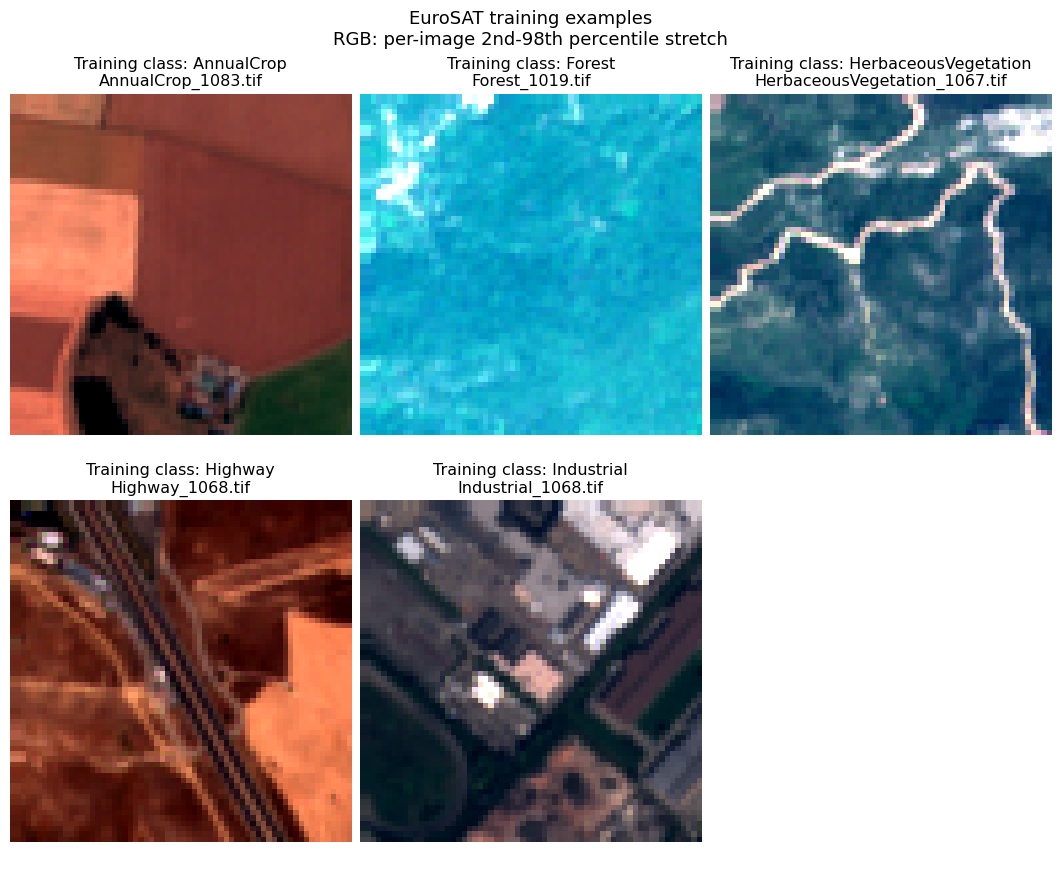

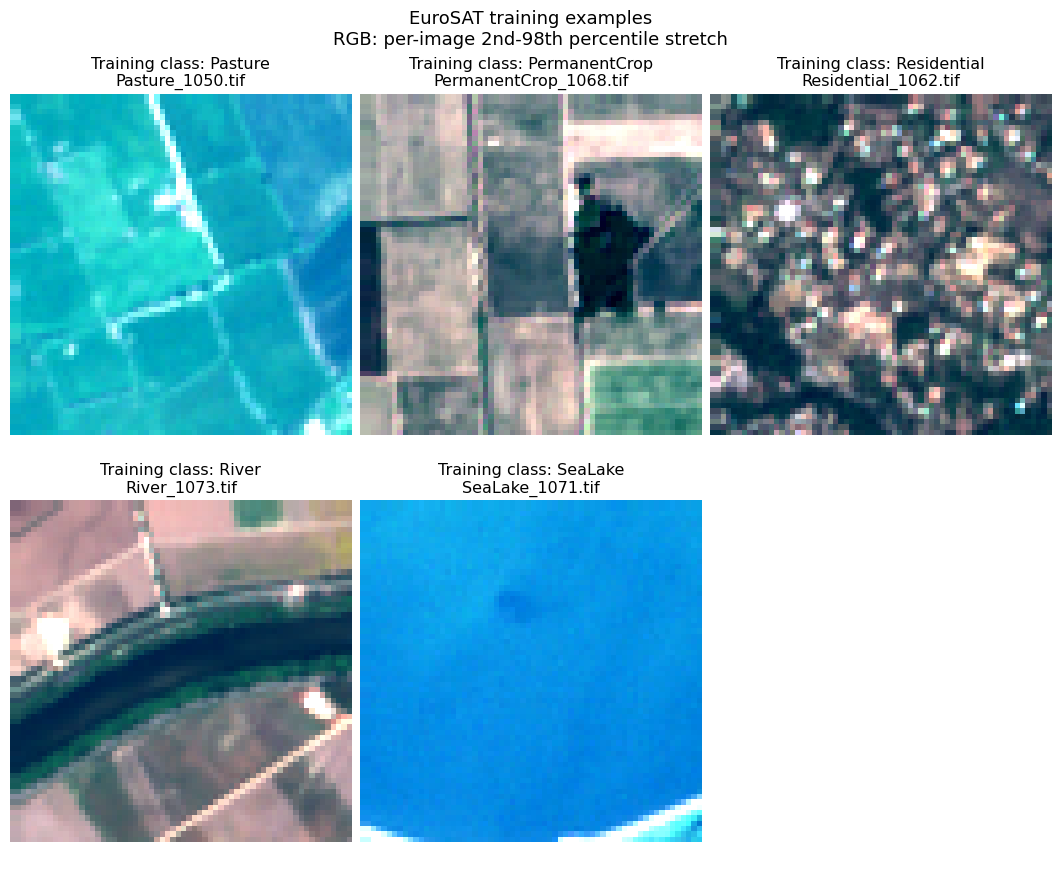

In [ ]:
# RGB is only a display: classification will use six spectral bands, not these pictures.
def show_tiles(rows, title, filename):
    # A two-by-three layout keeps image labels readable in the guide.
    fig, axes = plt.subplots(2, 3, figsize=(10.5, 8.6), layout="constrained")
    # Hide any unused panels when fewer than six examples are displayed.
    for axis in axes.flat:
        # Satellite tile coordinates are not needed for this visual inspection.
        axis.set_axis_off()
    # Rows may contain a training caption or the three methods' predicted classes.
    for axis, row in zip(axes.flat, rows):
        # Sentinel-2 bands 4, 3 and 2 correspond to visible red, green and blue.
        with rasterio.open(DATA / row["filename"]) as source:
            # Move the band dimension last for Matplotlib's RGB display.
            rgb = np.moveaxis(source.read([4, 3, 2]).astype("float32"), 0, -1)
        # Stretch each image for visibility without changing any classifier inputs.
        low, high = np.percentile(rgb, [2, 98])
        # Clipping limits the display to the valid RGB range.
        axis.imshow(np.clip((rgb - low) / (high - low), 0, 1))
        # The filename ties this illustration back to an actual EuroSAT image.
        axis.set_title(row["caption"] + "\n" + row["filename"], fontsize=11.5)
    # Label the figure and keep its original PNG for later reuse.
    display_note = "\nRGB: per-image 2nd-98th percentile stretch"
    # State the display rule alongside the exercise-specific figure title.
    fig.suptitle(title + display_note, fontsize=13)
    # Native figures stay separate from notebook screenshots.
    fig.savefig(RESULTS / filename, dpi=180)
    # Display this output directly underneath the code cell.
    plt.show()
    # Close the figure so repeated gallery calls do not accumulate open figures.
    plt.close(fig)


# Inspect only training-pool examples before evaluating the classifiers.
examples = images[images["split"] == "train"].sort_values("filename")
# One training example per class gives a first visual impression.
examples = examples.groupby("label", sort=True).first().reset_index()
# Keep the reference land-cover label visible above every tile.
examples["caption"] = "Training class: " + examples["label"]
# Split the ten examples into two readable figures.
for page in range(2):
    # Alphabetical class order makes the displayed selection repeatable.
    rows = examples.iloc[page * 5 : (page + 1) * 5].to_dict("records")
    # Save and display the same selected examples.
    show_tiles(rows, "EuroSAT training examples", f"class_examples_{page + 1}.png")

In [ ]:
# Summarize each image using simple measurements rather than a learned encoder.
def spectral_features(batch):
    # Sentinel-2 digital numbers are scaled to reflectance for the spectral summaries.
    values = batch * 0.0001
    # Six band means and six standard deviations describe brightness and variation.
    pieces = [values.mean(axis=(2, 3)), values.std(axis=(2, 3))]
    # Channel 3 is NIR; channels 2 and 5 are red and SWIR2 in our six-band array.
    for first, second in [(3, 2), (3, 5)]:
        # NDVI contrasts NIR with red; NBR contrasts NIR with SWIR2.
        denominator = values[:, first] + values[:, second]
        # Ignore near-zero denominators instead of creating infinite index values.
        index = np.divide(
            values[:, first] - values[:, second],
            denominator,
            # Missing index pixels are excluded from the summary below.
            out=np.full_like(denominator, np.nan),
            # Near-zero totals do not yield a stable spectral index.
            where=np.abs(denominator) > 1e-6,
        )
        # Add the mean and standard deviation of each vegetation-sensitive index.
        pieces.extend(
            [
                np.nanmean(index, axis=(1, 2))[:, None],
                # Variation retains information beyond the mean vegetation index.
                np.nanstd(index, axis=(1, 2))[:, None],
            ]
        )
    # Return one 16-feature row for every image in the batch.
    return np.concatenate(pieces, axis=1)


# This is a meaningful spectral baseline, rather than RGB-only comparison.
print("16 features: 6 band means + 6 band deviations + 4 NDVI/NBR summaries.")

16 features: 6 band means + 6 band deviations + 4 NDVI/NBR summaries.


In [ ]:
# Import the model architecture downloaded with the pretrained weights.
spec = importlib.util.spec_from_file_location("prithvi_model", MODEL / "prithvi_mae.py")
# Create the Python module that exposes PrithviViT.
module = importlib.util.module_from_spec(spec)
# Execute the architecture definition before constructing its encoder.
spec.loader.exec_module(module)
# The configuration provides the released architecture and band normalization values.
config = json.loads((MODEL / "config.json").read_text())["pretrained_cfg"]
# EuroSAT gives one 64-by-64 image per sample, not a temporal sequence.
config.update(img_size=64, num_frames=1)
# Freeze every model parameter; eval() also disables training-only layer behavior.
encoder = module.PrithviViT(**config).eval().requires_grad_(False)
# Read the pretrained checkpoint on CPU before moving the encoder to the GPU.
weights = torch.load(
    MODEL / "Prithvi_EO_V2_300M.pt",
    map_location="cpu",
    # Memory mapping avoids a second full checkpoint copy in RAM.
    weights_only=True,
    mmap=True,
)
# The checkpoint includes a decoder; only the encoder weights are needed here.
weights = {
    key.removeprefix("encoder."): value
    for key, value in weights.items()
    # Decoder parameters are irrelevant to image-feature extraction.
    if key.startswith("encoder.")
}
# Use positional embeddings appropriate for our 64-by-64, one-frame input grid.
weights["pos_embed"] = encoder.pos_embed
# Strict loading reports any missing or incompatible encoder parameters.
encoder.load_state_dict(weights, strict=True)
# Release the checkpoint mapping after its values have been copied into the encoder.
del weights
# Both the model and each input tensor must use the selected device.
encoder = encoder.to(DEVICE)
# Shape six means so NumPy broadcasts each value over its corresponding image band.
band_mean = np.asarray(config["mean"], dtype="float32")[None, :, None, None]
# Divide by the matching pretrained band standard deviations during normalization.
band_std = np.asarray(config["std"], dtype="float32")[None, :, None, None]
# No EuroSAT class labels have been supplied to the encoder.
print("Frozen Prithvi encoder ready on", next(encoder.parameters()).device)

Frozen Prithvi encoder ready on cuda:0


In [ ]:
# Keep matching rows for learned embeddings and conventional spectral summaries.
embedding_batches, statistics_batches = [], []
# Batches of 32 keep image tensors small enough for the free T4 runtime.
for start in range(0, len(images), 32):
    # Read the same rows for both feature methods.
    arrays = []
    # EuroSAT's source order differs from Prithvi's expected six-band order.
    for name in images["filename"].iloc[start : start + 32]:
        # Open one real multispectral tile at a time.
        with rasterio.open(DATA / name) as source:
            # Select blue, green, red, narrow NIR, SWIR1 and SWIR2, in that order.
            arrays.append(source.read([2, 3, 4, 13, 11, 12]).astype("float32"))
    # The batch shape is images by six bands by height by width.
    batch = np.stack(arrays)
    # Apply the conventional feature function to the same unaltered image batch.
    statistics_batches.append(spectral_features(batch))
    # Match the normalization used when Prithvi was pretrained.
    normalized = (batch - band_mean) / band_std
    # Inference mode avoids gradient storage because encoder weights are frozen.
    with torch.inference_mode():
        # Add a one-frame time dimension and move the input to the encoder's device.
        inputs = torch.from_numpy(normalized[:, :, None]).to(DEVICE)
        # Use the final encoder layer's class and spatial patch tokens.
        tokens = encoder.forward_features(inputs)[-1]
        # Exclude the class token and mean-pool the 16 spatial patch tokens.
        embedding_batches.append(tokens[:, 1:].mean(1).cpu().numpy())
    # Occasional progress confirms that encoding is advancing through the fixed image set.
    if start % 640 == 0:
        # Reading, normalization and inference all happen within this one pass.
        print("Encoded", min(start + 32, len(images)), "of", len(images), flush=True)
# Join batches without changing image order.
embeddings = np.concatenate(embedding_batches)
# Each conventional row describes exactly the same tile as its embedding row.
statistics = np.concatenate(statistics_batches)
# There should be one row per image in both representations.
print("Embedding shape:", embeddings.shape, "| Conventional shape:", statistics.shape)

Encoded 32 of 5300
Encoded 672 of 5300
Encoded 1312 of 5300
Encoded 1952 of 5300
Encoded 2592 of 5300
Encoded 3232 of 5300
Encoded 3872 of 5300
Encoded 4512 of 5300
Encoded 5152 of 5300
Embedding shape: (5300, 1024) | Conventional shape: (5300, 16)


In [ ]:
# Store reusable numerical features separately from the pretrained model.
feature_file = RESULTS / "features.npz"
# Save row identities too, so labels remain aligned after the file is reloaded.
np.savez_compressed(
    feature_file,
    embeddings=embeddings,
    statistics=statistics,
    # Filenames and split membership travel with their feature rows.
    filenames=images["filename"].to_numpy(dtype=str),
    # Unicode arrays load safely without Python object deserialization.
    labels=images["label"].to_numpy(dtype=str),
    # Classifier fitting must remain separate from held-out scoring.
    splits=images["split"].to_numpy(dtype=str),
)
# Save a readable table alongside the numerical feature file.
images.to_csv(RESULTS / "images.csv", index=False)
# Remove both the expensive encoder and the in-memory feature arrays.
del encoder, tokens, inputs, batch, arrays, normalized, embeddings, statistics
# Release batch references so the following cells must load their saved feature rows.
del embedding_batches, statistics_batches
# Return unused GPU memory to the runtime after the encoder is removed.
if DEVICE == "cuda":
    # No more model inference will be needed for any classifier fit below.
    torch.cuda.empty_cache()
# Make the reusable feature file visible in the cell output.
print("Saved:", feature_file.name, "| Encoder removed:", "encoder" not in globals())

Saved: features.npz | Encoder removed: True


In [ ]:
# Load the reusable feature file instead of running Prithvi again.
with np.load(feature_file, allow_pickle=False) as saved:
    # These are independent in-memory arrays reconstructed from the saved file.
    embeddings, statistics = saved["embeddings"], saved["statistics"]
    # Recover reference classes and split membership in exactly the saved row order.
    labels, splits = saved["labels"], saved["splits"]
# Integer class IDs are convenient for confusion matrices and prediction comparisons.
y = np.asarray([classes.index(label) for label in labels])
# Every classifier is assessed on the same held-out test rows.
test_rows = np.flatnonzero(splits == "test")
# Keep the 30 training candidates per class separate from all test images.
train_by_class = {c: np.flatnonzero((splits == "train") & (y == c)) for c in range(10)}
# Use a linear classifier for both representations to isolate their practical difference.
from sklearn.linear_model import LogisticRegression

# Also test nonlinear rules on the conventional feature table.
from sklearn.ensemble import RandomForestClassifier

# Scaling is learned only from each classifier's selected training rows.
from sklearn.pipeline import make_pipeline

# Standardization puts differently scaled feature dimensions on comparable scales.
from sklearn.preprocessing import StandardScaler

# Mean class recall gives each land-cover class equal weight despite unequal test counts.
from sklearn.metrics import balanced_accuracy_score, confusion_matrix


# Create a fresh classifier for every representation and label subset.
def make_classifier(kind):
    # Keep the two logistic-regression settings identical for a matched comparison.
    if kind == "logistic":
        # A pipeline fits its scaler on training rows without using test statistics.
        return make_pipeline(
            StandardScaler(),
            # The same regularization and solver limit apply to both tables.
            LogisticRegression(C=1, max_iter=2000, random_state=0),
        )
    # The forest uses the same label budget and test rows as both linear classifiers.
    return RandomForestClassifier(
        n_estimators=200,
        max_features="sqrt",
        # Fixed tree settings prevent test-driven tuning.
        min_samples_leaf=1,
        random_state=0,
        n_jobs=2,
    )


# Each tuple pairs one feature table with its downstream classifier choice.
methods = [
    ("Statistics + logistic", statistics, "logistic"),
    # A nonlinear baseline checks whether simple nonlinear rules close the gap.
    ("Statistics + forest", statistics, "forest"),
    # This classifier consumes saved embeddings; the encoder is already gone.
    ("Frozen 300M + logistic", embeddings, "logistic"),
]
# Confirm the expensive image model is absent before downstream learning begins.
print("Reloaded:", embeddings.shape, "| Encoder present:", "encoder" in globals())

Reloaded: (5300, 1024) | Encoder present: False


In [ ]:
# Repeated label subsets show whether the result depends on one lucky training selection.
seeds = [11, 22, 33]
# Keep all nine measured results and their full test predictions.
results, predictions = [], {}
# Each seed chooses the same 200 labelled training rows for all three methods.
for seed in seeds:
    # A dedicated generator makes the training selection repeatable.
    rng = np.random.default_rng(seed)
    # Shuffle each class separately before selecting 20 of its 30 candidates.
    orders = {c: rng.permutation(train_by_class[c]) for c in range(10)}
    # Twenty labels per class give a total training budget of 200 images.
    training = np.concatenate([orders[c][:20] for c in range(10)])
    # Every method sees the same training labels and the same test images.
    for name, values, kind in methods:
        # Start with an unfitted classifier rather than reusing a previous fit.
        classifier = make_classifier(kind)
        # Only the selected training rows can influence the classifier and its scaler.
        classifier.fit(values[training], y[training])
        # Test labels are not supplied when making these held-out predictions.
        predicted = classifier.predict(values[test_rows])
        # Retain predictions for the per-class analysis and image galleries.
        predictions[(name, seed)] = predicted
        # Balanced accuracy is the mean recall across all ten reference classes.
        score = balanced_accuracy_score(y[test_rows], predicted)
        # Store a separate score for every method and training-label subset.
        results.append({"method": name, "seed": seed, "mean_class_recall": score})
    # This progress line reports completed classifier fits, not encoder inference.
    print("Completed label subset", seed, flush=True)
# Show the three individual scores per method instead of only a single average.
scores = pd.DataFrame(results)
# Rows are methods; columns are the three fixed choices of labelled training images.
comparison = scores.pivot(index="method", columns="seed", values="mean_class_recall")
# Keep the underlying measured scores for later document formatting.
scores.to_csv(RESULTS / "classifier_scores.csv", index=False)
# Store the predictions separately so the evidence is reusable without retraining.
saved_predictions = {
    f"{name}|{seed}": value
    # Each key identifies one of the nine completed classifier fits.
    for (name, seed), value in predictions.items()
}
# This compact file preserves predictions without storing Python objects.
np.savez_compressed(RESULTS / "predictions.npz", **saved_predictions)
# Percentages make the class-recall table easy to interpret.
print((comparison * 100).round(2).to_string())

Completed label subset 11
Completed label subset 22
Completed label subset 33
seed                       11     22     33
method                                     
Frozen 300M + logistic  80.30  80.31  78.96
Statistics + forest     68.24  67.02  65.03
Statistics + logistic   67.64  67.05  66.44


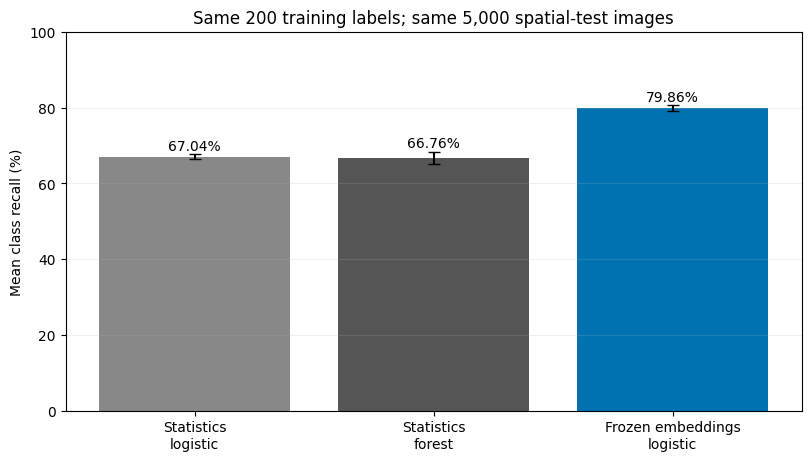

Embedding gain (percentage points):
method
Statistics + logistic    12.81
Statistics + forest      13.09


In [ ]:
# Use the same method order in every table and chart.
order = [name for name, _, _ in methods]
# Average the three training-label selections for each method.
means = comparison.loc[order].mean(axis=1) * 100
# The spread describes label-subset variation, not a confidence interval.
spread = comparison.loc[order].std(axis=1) * 100
# Compare learned features with both conventional classifiers in a single view.
fig, axis = plt.subplots(figsize=(8, 4.5), layout="constrained")
# Error bars show the standard deviation across the three label subsets.
axis.bar(
    range(3), means, yerr=spread, capsize=4, color=["#888888", "#555555", "#0072B2"]
)
# Short labels remain readable under the bars.
axis.set_xticks(
    range(3),
    [
        "Statistics\nlogistic",
        "Statistics\nforest",
        # The third bar uses learned rather than hand-designed features.
        "Frozen embeddings\nlogistic",
    ],
)
# The full percentage scale avoids visually exaggerating a difference.
axis.set_ylim(0, 100)
# Mean class recall weights each of EuroSAT's ten classes equally.
axis.set_ylabel("Mean class recall (%)")
# The title states the identical label budget and evaluation population.
axis.set_title("Same 200 training labels; same 5,000 spatial-test images")
# Add the measured mean above each bar.
for position, value in enumerate(means):
    # Keep each label above its error bar.
    axis.text(position, value + spread.iloc[position] + 1, f"{value:.2f}%", ha="center")
# Light gridlines make values easier to compare.
axis.grid(axis="y", alpha=0.2)
# Save the native chart independently of its notebook screenshot.
fig.savefig(RESULTS / "overall_comparison.png", dpi=180)
# Display the observed result below the code.
plt.show()
# Report the mean gain in percentage points rather than a relative percentage.
print("Embedding gain (percentage points):")
# Each subtraction compares exactly the same 5,000 test tiles.
print((means.iloc[2] - means.iloc[:2]).round(2).to_string())

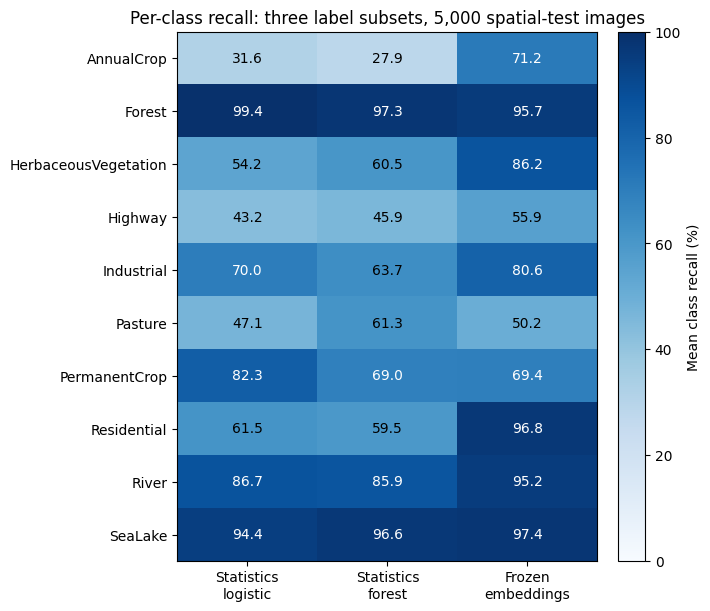

In [ ]:
# Aggregate recalls class by class so a high overall score cannot hide every regression.
class_recalls = {name: [] for name, _, _ in methods}
# Preserve all three labelled-training selections in the per-class comparison.
for name, _, _ in methods:
    # Each confusion matrix compares predictions with the same held-out reference labels.
    for seed in seeds:
        # Rows are reference classes and columns are predicted classes.
        matrix = confusion_matrix(
            y[test_rows],
            predictions[(name, seed)],
            # Include every class in a consistent row/column order.
            labels=np.arange(10),
        )
        # Class recall is the diagonal count divided by that class's full test population.
        class_recalls[name].append(matrix.diagonal() / matrix.sum(axis=1))
# Average each class's recall across the three training subsets.
recall_table = pd.DataFrame(
    {
        name: np.mean(values, axis=0)
        # Preserve a column for each evaluated representation/method.
        for name, values in class_recalls.items()
    },
    index=classes,
)
# Keep the measured table alongside its native plot.
recall_table.to_csv(RESULTS / "per_class_recall.csv")
# Percentages make the table and plot use the same units.
values = recall_table[order].to_numpy() * 100
# A heatmap shows both gains and losses across the ten land-cover classes.
fig, axis = plt.subplots(figsize=(7, 6), layout="constrained")
# Fix the color scale across all methods and classes.
heatmap = axis.imshow(values, vmin=0, vmax=100, cmap="Blues", aspect="auto")
# The column order matches the overall comparison.
axis.set_xticks(
    range(3),
    [
        "Statistics\nlogistic",
        "Statistics\nforest",
        # All columns describe the same held-out images.
        "Frozen\nembeddings",
    ],
)
# Retain all ten classes rather than displaying only the largest gains.
axis.set_yticks(range(10), classes)
# Numeric labels allow exact comparisons beyond the color shading.
for row in range(10):
    # Write all three measured recalls for this reference class.
    for column in range(3):
        # White labels remain readable in the darker cells.
        text_color = "white" if values[row, column] > 65 else "black"
        # Center the measured recall inside its class/method cell.
        axis.text(
            column,
            row,
            f"{values[row, column]:.1f}",
            ha="center",
            # A contrasting font makes both high and low recall values legible.
            va="center",
            color=text_color,
        )
# The title identifies the evaluation population and averaging rule.
axis.set_title("Per-class recall: three label subsets, 5,000 spatial-test images")
# The colorbar explains the common percentage scale.
fig.colorbar(heatmap, ax=axis, label="Mean class recall (%)")
# Save a reusable figure before displaying it in the notebook.
fig.savefig(RESULTS / "per_class_recall.png", dpi=180)
# Inspect weak classes as well as classes with high recall.
plt.show()

In [ ]:
# Use the first label subset consistently for every qualitative illustration below.
seed = seeds[0]
# Keep the test rows in the same order as every stored prediction array.
cases = images[images["split"] == "test"].reset_index(drop=True).copy()
# Attach each method's predicted class name to the corresponding real image.
for column, name in [("FM", order[2]), ("LR", order[0]), ("RF", order[1])]:
    # Convert integer predictions back to the readable EuroSAT class names.
    cases[column] = [classes[value] for value in predictions[(name, seed)]]
# These masks identify agreements and disagreements against the reference class.
fm_ok, lr_ok, rf_ok = [cases[column] == cases["label"] for column in ["FM", "LR", "RF"]]
# Every displayed prediction is included directly in the image caption.
cases["caption"] = (
    "Truth: "
    + cases["label"]
    + "\nFM: "
    + cases["FM"]
    # Include both conventional predictions in every displayed case.
    + "\nLR: "
    + cases["LR"]
    + "\nRF: "
    + cases["RF"]
)
# Count the full population from which illustrative cases are selected.
populations = cases.groupby("label").size().to_frame("test_images")
# Record both foundation-model wins and the opposite outcome.
groups = [
    ("all_correct", fm_ok & lr_ok & rf_ok),
    # An FM win requires both conventional methods to be wrong.
    ("FM_win", fm_ok & ~lr_ok & ~rf_ok),
    # Keep the opposite outcome visible to avoid a one-sided comparison.
    ("FM_loss", ~fm_ok & lr_ok & rf_ok),
]
# Count each outcome across the whole test set before selecting illustrations.
for name, mask in groups:
    # Missing class/group combinations have zero eligible cases, not missing measurements.
    populations[name] = (
        cases[mask].groupby("label").size().reindex(classes, fill_value=0)
    )
# Preserve the case identities and their predictions for later formatting.
cases.to_csv(RESULTS / "image_predictions_seed11.csv", index=False)
# The full counts prevent a few selected images from standing in for an accuracy estimate.
populations.to_csv(RESULTS / "example_populations_seed11.csv")
# Inspect how common each type of success or failure actually is.
print(populations.to_string())

                      test_images  all_correct  FM_win  FM_loss
label                                                          
AnnualCrop                    778          150     323       16
Forest                       1037          973       1       41
HerbaceousVegetation          776          372     141       11
Highway                       300           97      47       23
Industrial                    313          166      55       20
Pasture                        75           28       3        9
PermanentCrop                 267          169       4       30
Residential                   467          231     157        3
River                         291          229      25        5
SeaLake                       696          645      12        3


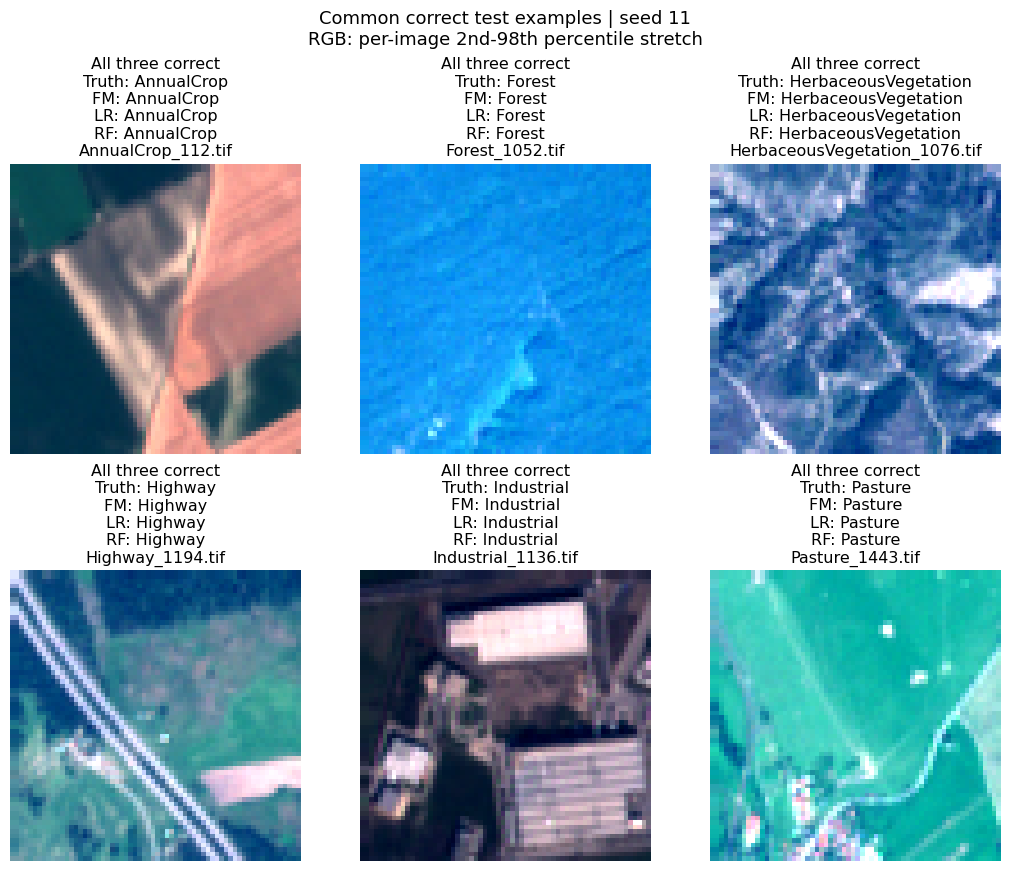

In [ ]:
# Begin with agreement cases before inspecting disagreements.
common = cases[fm_ok & lr_ok & rf_ok].sort_values("filename")
# Use the first eligible filename in each of six alphabetical classes.
rows = [common[common["label"] == label].iloc[0].to_dict() for label in classes[:6]]
# Keep the case type visible above the reference and predicted classes.
for row in rows:
    # A common success is useful context but does not establish superiority.
    row["caption"] = "All three correct\n" + row["caption"]
# Display the exact images and every method's prediction together.
show_tiles(rows, "Common correct test examples | seed 11", "common_correct.png")

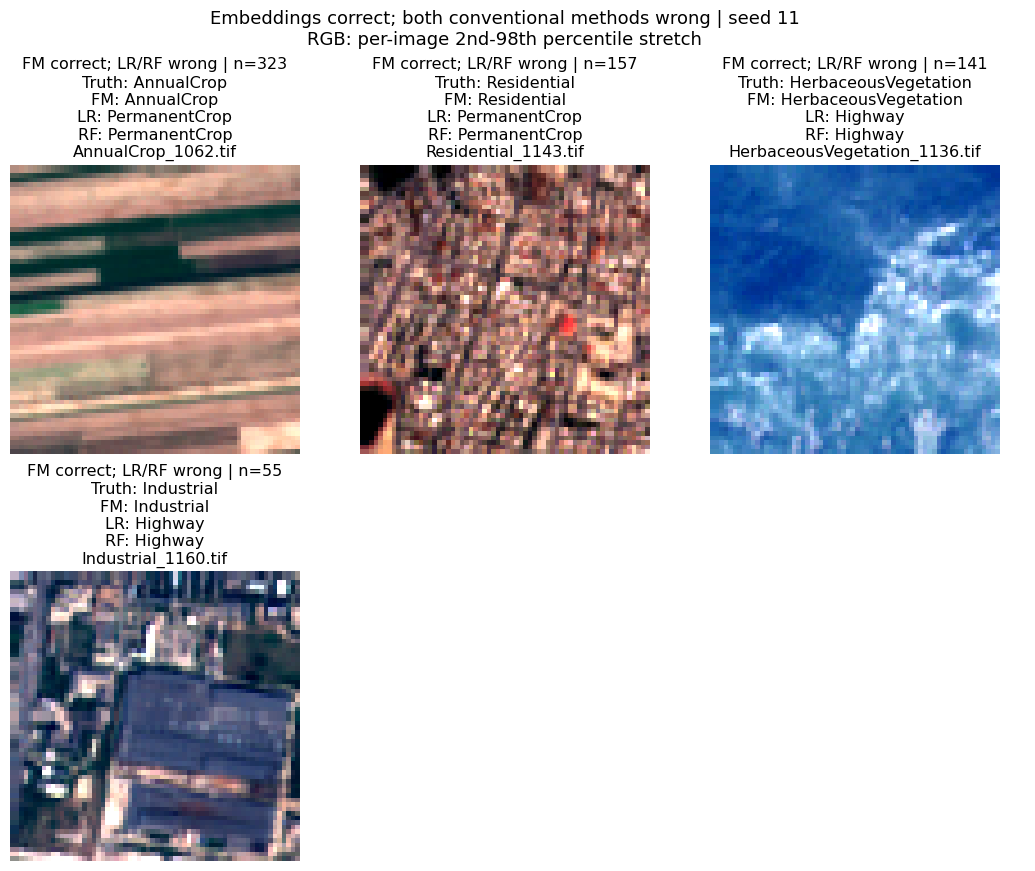

               class  FM_win  test_images
          AnnualCrop     323          778
         Residential     157          467
HerbaceousVegetation     141          776
          Industrial      55          313
             Highway      47          300
               River      25          291
             SeaLake      12          696
       PermanentCrop       4          267
             Pasture       3           75
              Forest       1         1037


In [ ]:
# Rank classes by their full count of FM-correct, both-baselines-wrong test cases.
ranked = populations.reset_index(names="class")
# Break equal population counts alphabetically for a repeatable selection.
ranked = ranked.sort_values(["FM_win", "class"], ascending=[False, True])
# Select four classes with the most eligible cases; alphabetical order breaks ties.
win_classes = ranked["class"].head(4)
# These are conditional examples selected after evaluation, not a random accuracy sample.
rows = []
# Show one repeatable example from each selected class.
for label in win_classes:
    # Keep only FM-correct cases with both conventional predictions wrong.
    eligible = cases[fm_ok & ~lr_ok & ~rf_ok & (cases["label"] == label)]
    # Choosing the first filename avoids searching visually for a persuasive-looking tile.
    row = eligible.sort_values("filename").iloc[0].to_dict()
    # State how many cases in this class satisfy the same condition.
    row["caption"] = f"FM correct; LR/RF wrong | n={len(eligible)}\n" + row["caption"]
    # Carry the real filename and all three predictions into the display.
    rows.append(row)
# Display the retained cases using the same RGB stretch as the earlier galleries.
show_tiles(
    rows,
    "Embeddings correct; both conventional methods wrong | seed 11",
    # The native file preserves the exact illustrated case selection.
    "embedding_wins.png",
)
# The population counts show that these selected cases belong to larger outcome groups.
print(ranked[["class", "FM_win", "test_images"]].to_string(index=False))

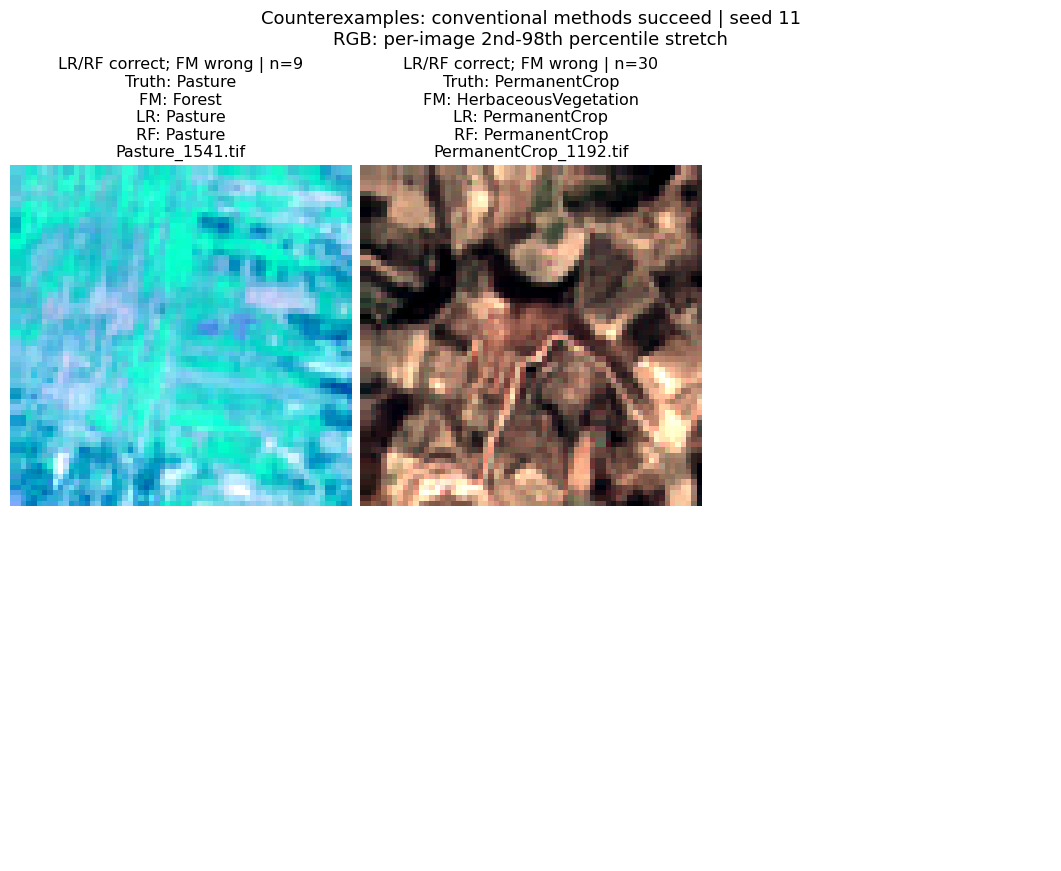

All nine classifiers used saved features after the encoder was removed.
Inspect all scores and class recalls; embeddings do not win on every image.


In [ ]:
# Include cases where conventional features support the better prediction.
rows = []
# Use the same two counterexample classes on every run.
for label in ["Pasture", "PermanentCrop"]:
    # Select conventional successes that the embedding classifier misses.
    eligible = cases[~fm_ok & lr_ok & rf_ok & (cases["label"] == label)]
    # Apply the same first-filename rule used for the embedding-win examples.
    row = eligible.sort_values("filename").iloc[0].to_dict()
    # Report the size of the outcome group instead of implying the image is typical.
    row["caption"] = f"LR/RF correct; FM wrong | n={len(eligible)}\n" + row["caption"]
    # Preserve the filename and all predicted labels for the final montage.
    rows.append(row)
# The same display stretch applies to successes and failures.
show_tiles(
    rows,
    "Counterexamples: conventional methods succeed | seed 11",
    # Keep these limitations beside the other reusable evidence figures.
    "counterexamples.png",
)
# The same saved embeddings supported every downstream fit without reloading Prithvi.
print("All nine classifiers used saved features after the encoder was removed.")
# The observed advantage is specific to this dataset, label budget and evaluation design.
print("Inspect all scores and class recalls; embeddings do not win on every image.")